# Students Performance: Data Analysis and Machine Learning

## Project Overview

This project explores the **Students Performance in Exams** dataset through data inspection and cleaning, exploratory data analysis, visualisation, and introductory machine-learning experiments.

The analysis asks six questions:
- How are maths, reading and writing scores related?
- How does average performance differ by test-preparation status?
- How are scores distributed across the grading bands used in this project?
- How does performance vary across parental education levels?
- How does performance vary by gender and subject?
- How does performance vary across race/ethnicity groups?

The modelling section compares regression models for predicting average scores and classification models for predicting pass/fail results.

**Note:** The grade boundaries and pass mark are project-defined. Group differences are descriptive associations, not evidence that one factor caused a particular outcome.


## Cleaning and Analysing Students Performance

### 1. Data Cleaning and Investigation

In [ ]:
#Importing all the necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("seaborn-v0_8")
print("Setup Completed")

Setup Completed


In [ ]:
# Load in the data
DATA_PATH = Path("data/students_performance.csv")

# Also allow the CSV to sit beside this notebook.
if not DATA_PATH.exists():
    DATA_PATH = Path("students_performance.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Place students_performance.csv in the project "
        "root or inside the data/ folder."
    )

raw = pd.read_csv(DATA_PATH)
students_data = raw.copy()
print(f"Loaded dataset from: {DATA_PATH.resolve()}")

In [ ]:
# Print out first 10 rows from the dataset
students_data.head(10)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
5,female,group B,associate's degree,standard,none,71,83,78
6,female,group B,some college,standard,completed,88,95,92
7,male,group B,some college,free/reduced,none,40,43,39
8,male,group D,high school,free/reduced,completed,64,64,67
9,female,group B,high school,free/reduced,none,38,60,50


In [ ]:
# Let's standardize the column names
students_data.columns = students_data.columns.str.strip().str.lower().str.replace(" ", "_")
students_data

,gender,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [ ]:
# Let's investigate the data
print(f"The Student's Performance dataset has:\n{students_data.shape[0]} rows and {students_data.shape[1]} columns")
print(f"{students_data.duplicated().sum()} duplicated rows")
print(f"{students_data.isna().sum().sum()} rows with empty values")

The Student's Performance dataset has:
1000 rows and 8 columns
0 duplicated rows
0 rows with empty values


In [ ]:
# Now let's investigate how many "None" or "Unknown" values are under each column
count = students_data.select_dtypes(str).apply(lambda val: val.str.strip().str.lower().isin(["none", "unknown"]))
summary = count.sum().reset_index()
summary.columns = ["Column", "Count"]
print(summary)

                        Column  Count
0                       gender      0
1               race/ethnicity      0
2  parental_level_of_education      0
3                        lunch      0
4      test_preparation_course    642


From the summary above, we can see that column `test_preparation_course` has 642 of its rows equal to **none** or **unknown**. <br>Let's investigate further to find out why

In [ ]:
students_data["test_preparation_course"].value_counts()

test_preparation_course
none         642
completed    358
Name: count, dtype: int64

From the code above, we can now verify that the **"none"** values used in the `test_preparation_course` column is perfectly acceptable as it was used in categorizing the column into `none` and `completed`.<br>

In [ ]:
# So now let's investigate what are present in the other alphabetic columns
for column in students_data.select_dtypes("str").columns:
    print(f"This is a brief summary of the values present in the {column.title().replace("_", " ")} column coupled with their total number:\n{students_data[column].value_counts().sort_index()}\n")

This is a brief summary of the values present in the Gender column coupled with their total number:
gender
female    518
male      482
Name: count, dtype: int64

This is a brief summary of the values present in the Race/Ethnicity column coupled with their total number:
race/ethnicity
group A     89
group B    190
group C    319
group D    262
group E    140
Name: count, dtype: int64

This is a brief summary of the values present in the Parental Level Of Education column coupled with their total number:
parental_level_of_education
associate's degree    222
bachelor's degree     118
high school           196
master's degree        59
some college          226
some high school      179
Name: count, dtype: int64

This is a brief summary of the values present in the Lunch column coupled with their total number:
lunch
free/reduced    355
standard        645
Name: count, dtype: int64

This is a brief summary of the values present in the Test Preparation Course column coupled with their total 

If we take a closer look at the Parental Level of Education column, we can see that some rows contain `high school` and some contain `some high school`. This should not be altered as there is a useful distinction between them, which is that those rows with `some high school` means the parenst could not finish high school and those with `high school` means high schoool was completed.

Lastly, before we go into the analysis, it is important we generate the `total_score`, `average_score`, `grade` and `result` columns as they would be essential in our analysis.

In [ ]:
students_data["total_score"] = students_data["math_score"] + students_data["reading_score"] + students_data["writing_score"]
students_data["average_score"] = round(students_data["total_score"]/3, 1)

bins = [0, 40, 45, 50, 55, 60, 65, 70, 75, 101]
grades = ["F9", "E8", "D7", "C6", "C5", "C4", "B3", "B2", "A1"]

students_data["grade"] = pd.cut(
    students_data["average_score"], 
    bins=bins, 
    labels=grades,
    right=False
)

students_data["result"] = students_data["average_score"].ge(50).map({
    True: "pass",
    False: "fail"
    })

# For more information on the function pd.cut(), run the code below
# help(pd.cut)

Now, we can safely move on to analyzing and visualizing the data!

### 2. Data Analysis and Visualization

In [ ]:
# Let's start by printing the first 20 rows from the data
students_data.head(20)

,gender,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score,grade,result
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.7,B2,pass
1,female,group C,some college,standard,completed,69,90,88,247,82.3,A1,pass
2,female,group B,master's degree,standard,none,90,95,93,278,92.7,A1,pass
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.3,D7,fail
4,male,group C,some college,standard,none,76,78,75,229,76.3,A1,pass
5,female,group B,associate's degree,standard,none,71,83,78,232,77.3,A1,pass
6,female,group B,some college,standard,completed,88,95,92,275,91.7,A1,pass
7,male,group B,some college,free/reduced,none,40,43,39,122,40.7,E8,fail
8,male,group D,high school,free/reduced,completed,64,64,67,195,65.0,B3,pass
9,female,group B,high school,free/reduced,none,38,60,50,148,49.3,D7,fail


In [ ]:
# Let's define a grouping function that uses mean 
def group(a, b):
    group = round(students_data.groupby(a)[b].mean().sort_index(), 2)
    return group

def update_grouping(groupings, column):
    print(f"These are the different groupings for the average scores for each subject corresponding to each {column.replace("_", " ")}:\n")
    for score in subject_scores:
        grouping = group(column, score)
        groupings.append(grouping)
        print(grouping, end="\n\n")
        
subject_scores = ["math_score", "reading_score", "writing_score", "average_score"]

##### So, with our analysis, we hope to answer 6 main questions namely:
1.  **Is there a relationship between students' reading, writing and maths scores?** <br><br>
2.  **Is there a difference in average academic performance between students who completed the test preparation course and those who didn't?** <br><br>
3.  **How are students' average scores distributed, and what proportion fall into different performance bands?** <br><br>
4.  **Are there differences in students' academic performance across their parents' education levels?** <br><br>
5.  **How does academic performance vary by gender and does the pattern differ between subjects?** <br><br>
6.  **Are there differences in students' academic performance across their race/ethnicity?** <br><br>

##### 1.  **Is there a relationship between students' reading, writing and maths scores?**

For this question, the *students_data* `reading_score`, `writing_score` and `math_score` columns would be needed. We would also be creating scatter plots for each pair of subjects and also a correlation matrix. <br>**Then let's get into the analysis!**

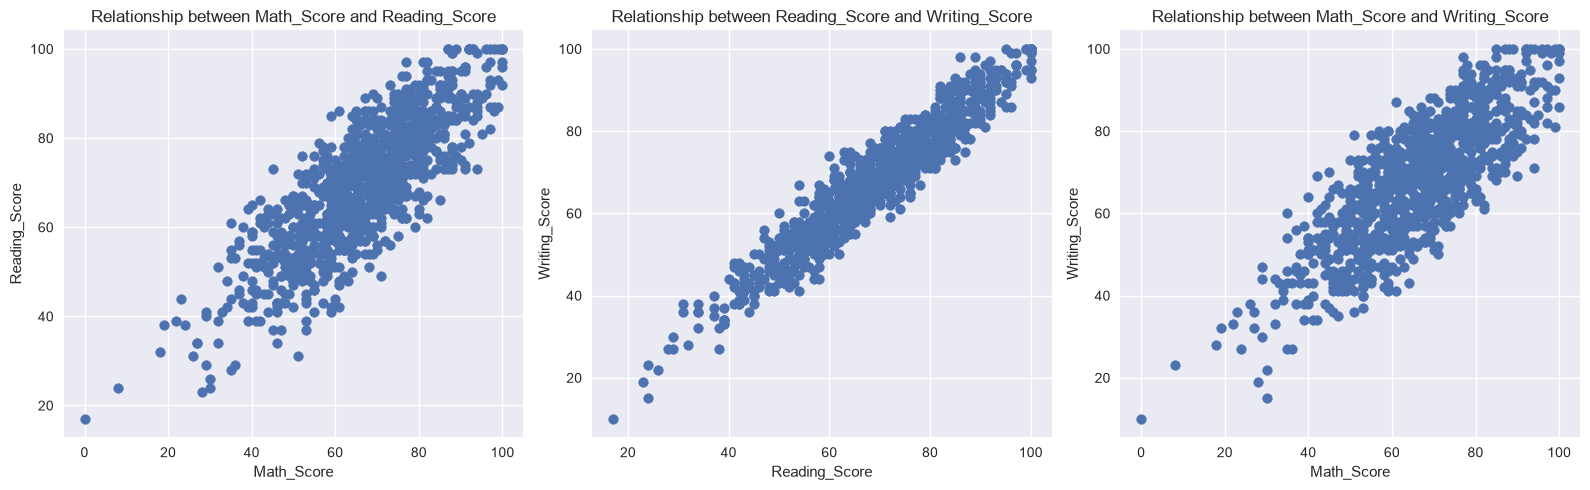

In [ ]:
# Let's start by creating the pairs
relationship_pairs = [("math_score", "reading_score"), 
                      ("reading_score", "writing_score"), 
                      ("math_score", "writing_score")]

fig, axes = plt.subplots(1, 3, figsize = (16, 5))

for ax, (x, y) in zip(axes, relationship_pairs):
    ax.scatter(students_data[x], students_data[y])
    ax.set_xlabel(x.title())
    ax.set_ylabel(y.title())
    ax.set_title(f"Relationship between {x.title()} and {y.title()}")

plt.tight_layout()
plt.show()

##### My Thoughts:
From the scatter plots above I can observe that:
1. There appears to be a positive relationship between the `Math` scores and the `Reading` scores of the students and so this means that if a student has a high Math score, he/she, all other factors being equal, would most likely also have a high Reading score and vice versa . Also the strength of the relationship between them appears a bit higher around the 50 to 90 score range as thats where the values appears to be more clustered together. **(Scatter Plot 1)** <br><br>
2. There appears to be a positive relationship between the `Reading` scores and the `Writing` scores of the students and so this means that if a student has a high Reading score, he/she, all other factors being equal, would most likely also have a high Writing score and vice versa. Also the strength of the relationship between them appears even more relatively high as their values are relatively closer especially around the 40 to 100 score range. **(Scatter Plot 2)** <br><br>
3. There appears to be a positive relationship between the `Math` scores and the `Writing` scores of the students and so this means that if a student has a high Math score, he/she, all other factors being equal, would most likely also have a high Writing score and vice versa. Also the strength of the relationship between them appears as high as that of the Math scores. Their values in this relationship are are sparsely dispersed and appears much closer around the 40 to 100 score range. **(Scatter Plot 3)** <br><br>

In [ ]:
#Correlation Matrix
students_data[["math_score", "reading_score", "writing_score"]].corr()

,math_score,reading_score,writing_score
math_score,1.000000,0.817580,0.802642
reading_score,0.817580,1.000000,0.954598
writing_score,0.802642,0.954598,1.000000


##### Conclusion:
With the correlation matrix above, I can conclude that:
1. There is in fact a positive relationship between `Math` scores and `Reading` scores and their relationship is very strong **(with a Correlation Coefficient of 0.817580)**, even stronger than that which exists between Math and Writing scores. <br><br>
2. There is also a positive relationship between `Reading` scores and `Writing` scores and their relationship is the strongest amongst all the relationships **(with a Correlation Coefficient of 0.954598)** <br><br>
3. There is also a positive relationship between `Math` scores and `Writing` scores and their relationship is also very strong but is the weakest amongst all the relationships **(with a Correlation Coefficient of 0.802642)** <br><br>

##### 2. **Is there a difference in average academic performance between students who completed the test preparation course and those who didn't?**

To answer this question, the *students_data* `test_preparation_course`, `reading_score`, `writing_score` and `math_score` columns would be needed. We would also be plotting a multiple bar chart for the visualization and analysis. <br>**Then let's get into the analysis!**


                          math_score  reading_score  writing_score  \
test_preparation_course                                             
completed                     69.70          73.89          74.42   
none                          64.08          66.53          64.50   

                         average_score  
test_preparation_course                 
completed                        72.67  
none                             65.04   



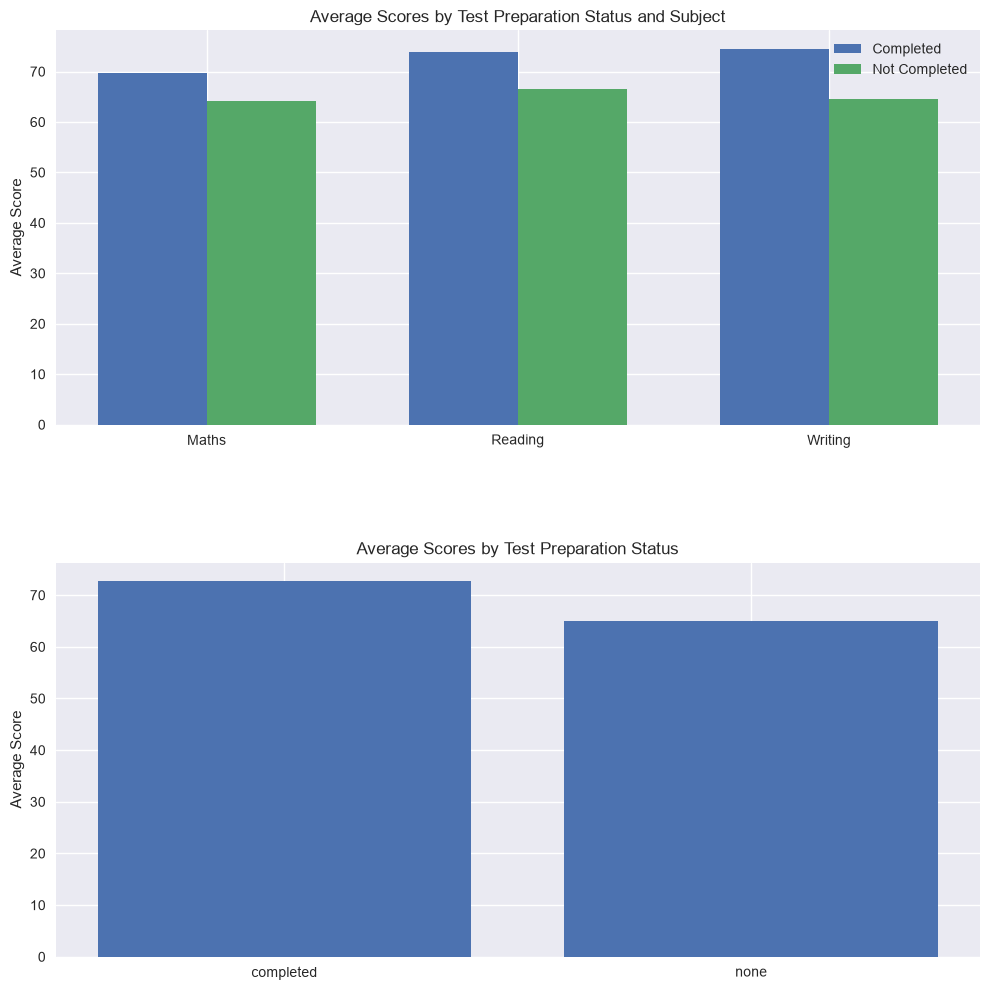

In [ ]:
# Let's start by grouping each state of test_preparation_course with the mean of their corresponding math, reading and writing score
test_preparation_average = group("test_preparation_course", subject_scores)
print("\n", test_preparation_average, "\n")

subjects = ["Maths", "Reading", "Writing"]

completed = test_preparation_average.loc["completed"][:-1]
not_completed = test_preparation_average.loc["none"][:-1]

x = np.arange(len(subjects))
# Returns a list of 0, to total number of subjects which is 3
width = 0.35

fig, axes = plt.subplots(2, 1, figsize = (10, 10))
# plt.bar() function creates a bar chart and collects these values
# plt.bar(position, height, width, label) though label is not important
axes[0].bar(x - width/2, completed, width, label="Completed")
axes[0].bar(x + width/2, not_completed, width, label="Not Completed")
axes[0].set_xticks(x)
axes[0].set_xticklabels(subjects)
axes[0].set_ylabel("Average Score")
axes[0].set_title("Average Scores by Test Preparation Status and Subject")
axes[0].legend()

axes[1].bar(range(len(test_preparation_average)), test_preparation_average["average_score"])
axes[1].set_xticks(range(len(test_preparation_average)))
axes[1].set_xticklabels(test_preparation_average.index)
axes[1].set_ylabel("Average Score")
axes[1].set_title("Average Scores by Test Preparation Status")
plt.tight_layout()
plt.subplots_adjust(hspace=0.35)
plt.show()

##### Conclusion:
*Yes, there is a difference in average academic performance between those who completed their test preparation course and those who didn't.* <br> From the chart, we can see that the average score of those who completed their test preparation course is noticeably higher than that of those who didn't. However this analysis cannot establish that completing the course alone caused higher scores and only proves there is an association between completing one's test preparation course and a high academic performance. <br><br>

##### 3. How are students' average scores distributed, and what proportion fall into different performance bands?

For this question, the *students_data* `average_score` and `grade` columns would be needed. We would also be creating bar plots for the grades and also a pie chart to illustrate the distribution. For this analysis, I would be using the grade A1 to F9 grade scale and would also be classifying scores of 50 and above as passing since no reliable grading scale accompanied the dataset.<br>**Then let's get into the analysis!**

In [ ]:
# Let's start by grouping the grades column in such a way that each grade is accompanied by the number the rows that have this grade are.
grade_grouping = students_data.groupby("grade")["grade"].count().sort_index()
grades_categories = ["A1\n(75 - 100)", "B2\n(70 - 74)", "B3\n(65 - 69)", "C4\n(60 - 64)", "C5\n(55 - 59)", "C6\n(50 - 54)", "D7\n(45 - 49)", "E8\n(40 - 44)", "F9\n(0 - 39)"]
grade_order = sorted(students_data["grade"].unique())
grade_grouping = grade_grouping.reindex(grade_order, fill_value=0)
print(f"Grouping of Students according to Grades\n{grade_grouping}\n")

# Now we group the students according to their results, whether Pass or Fail
result_grouping = students_data.groupby("result")["result"].count()
print(f"Grouping of Students according to Result\n{result_grouping}\n")

Grouping of Students according to Grades
grade
A1    324
B2    135
B3    142
C4    114
C5     94
C6     88
D7     49
E8     24
F9     30
Name: grade, dtype: int64

Grouping of Students according to Result
result
fail    103
pass    897
Name: result, dtype: int64



In [ ]:
# Lets create a color palette for each grade for fun
palette = sns.color_palette("colorblind", len(grade_grouping))
pie_colors = [palette[i] for i, name in enumerate(grade_grouping.index)]

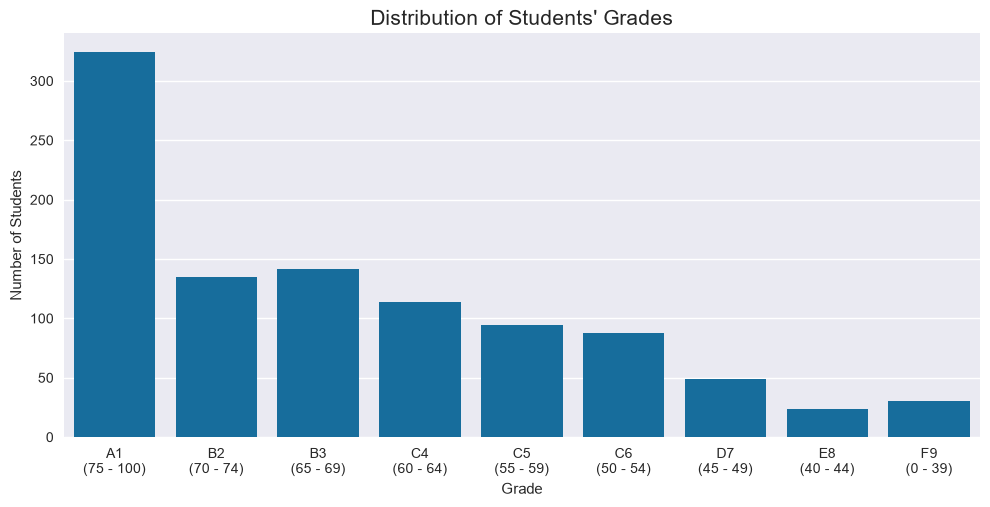

In [ ]:
# Now to plotting the bar chart
plt.figure(figsize=(10, 5))
sns.barplot(grade_grouping, color=palette[0])
# This blue is lowkey better than Jupyter's default blue
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.title("Distribution of Students' Grades", {'fontsize':15})
plt.tight_layout()
plt.xticks(range(len(grades_categories)), grades_categories)
plt.show()

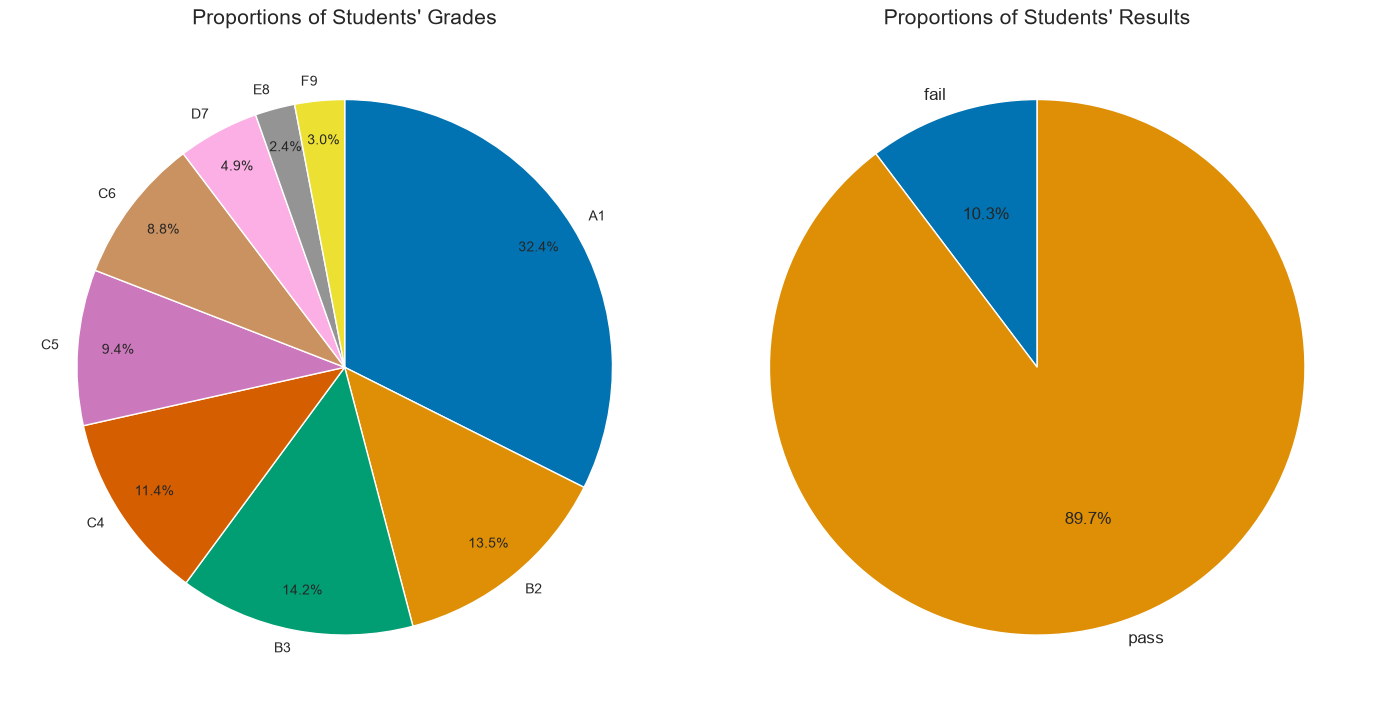

In [ ]:
# Plotting of the pie charts
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].pie(x=grade_grouping, labels=grade_grouping.index, colors=pie_colors, autopct="%1.1f%%",
       startangle=90, counterclock=False, pctdistance=0.85, labeldistance=1.07, textprops = {"size": 10}, 
       wedgeprops={"edgecolor": "white", "linewidth": 1.0})
ax[0].set_title("Proportions of Students' Grades", {'fontsize':15})
ax[1].pie(x=result_grouping, labels=result_grouping.index, colors=[palette[0], palette[1]], autopct="%1.1f%%",
       startangle=90, counterclock=True, pctdistance=0.6, labeldistance=1.07, textprops = {"size": 12}, 
       wedgeprops={"edgecolor": "white", "linewidth": 1.0})
ax[1].set_title("Proportions of Students' Results", {'fontsize':15})
plt.tight_layout()
plt.show()

# For more information on creating pie charts, run the code below
# help(plt.pie)

##### Conclusion:
From the bar and pie charts of Distribution of Students' Grades, we can see that, according to the grading scale used in this analysis, the A1 grade carries the highest number of students or the highest percentage of students with 324 students and 32.4%, followed by:
- B3 (142 students, 14.2%), <br><br>
- B2 (135 students, 13.5%), <br><br>
- C4 (114 students, 11.4%), <br><br>
- C5 (94 students, 9.4%), <br><br>
- C6 (88 students, 8.8%), <br><br>
- D7 (49 students, 4.9%), <br><br>
- F9 (30 students, 3.0%) and finally <br><br>
- E8 (24 students, 2.4%) <br><br>
This goes to show that more students passed than failed. 
This is further confirmed by the pie chart showing the **Distribution of Students' Results** which shows us that a massive 89.7% of students passed and only 10.3% failed. <br><br>

##### 4.  **Are there differences in students' academic performance across their parents' education levels?**

For this question, we would be needing the *students_data* `parental_level_of_education`, `math_score`, `reading_score`, `writing_score` and `average_score` columns. We would also be creating a bar chart for each subject to show the distribution of each subject's average score according to the students parental level of education. <br>**Then let's get into the analysis!**

In [ ]:
# We would start by grouping all the rows under the "parental_level_of_education" column with its respective
# average score under each subject and then the general average score
groupings_by_parental_level = []
update_grouping(groupings_by_parental_level, "parental_level_of_education")

print(f"This grouping below also shows how many students belong to each parental level of education\n\n{students_data["parental_level_of_education"].value_counts()}")

These are the different groupings for the average scores for each subject corresponding to each parental level of education:

parental_level_of_education
associate's degree    67.88
bachelor's degree     69.39
high school           62.14
master's degree       69.75
some college          67.13
some high school      63.50
Name: math_score, dtype: float64

parental_level_of_education
associate's degree    70.93
bachelor's degree     73.00
high school           64.70
master's degree       75.37
some college          69.46
some high school      66.94
Name: reading_score, dtype: float64

parental_level_of_education
associate's degree    69.90
bachelor's degree     73.38
high school           62.45
master's degree       75.68
some college          68.84
some high school      64.89
Name: writing_score, dtype: float64

parental_level_of_education
associate's degree    69.57
bachelor's degree     71.93
high school           63.10
master's degree       73.60
some college          68.47
some high 

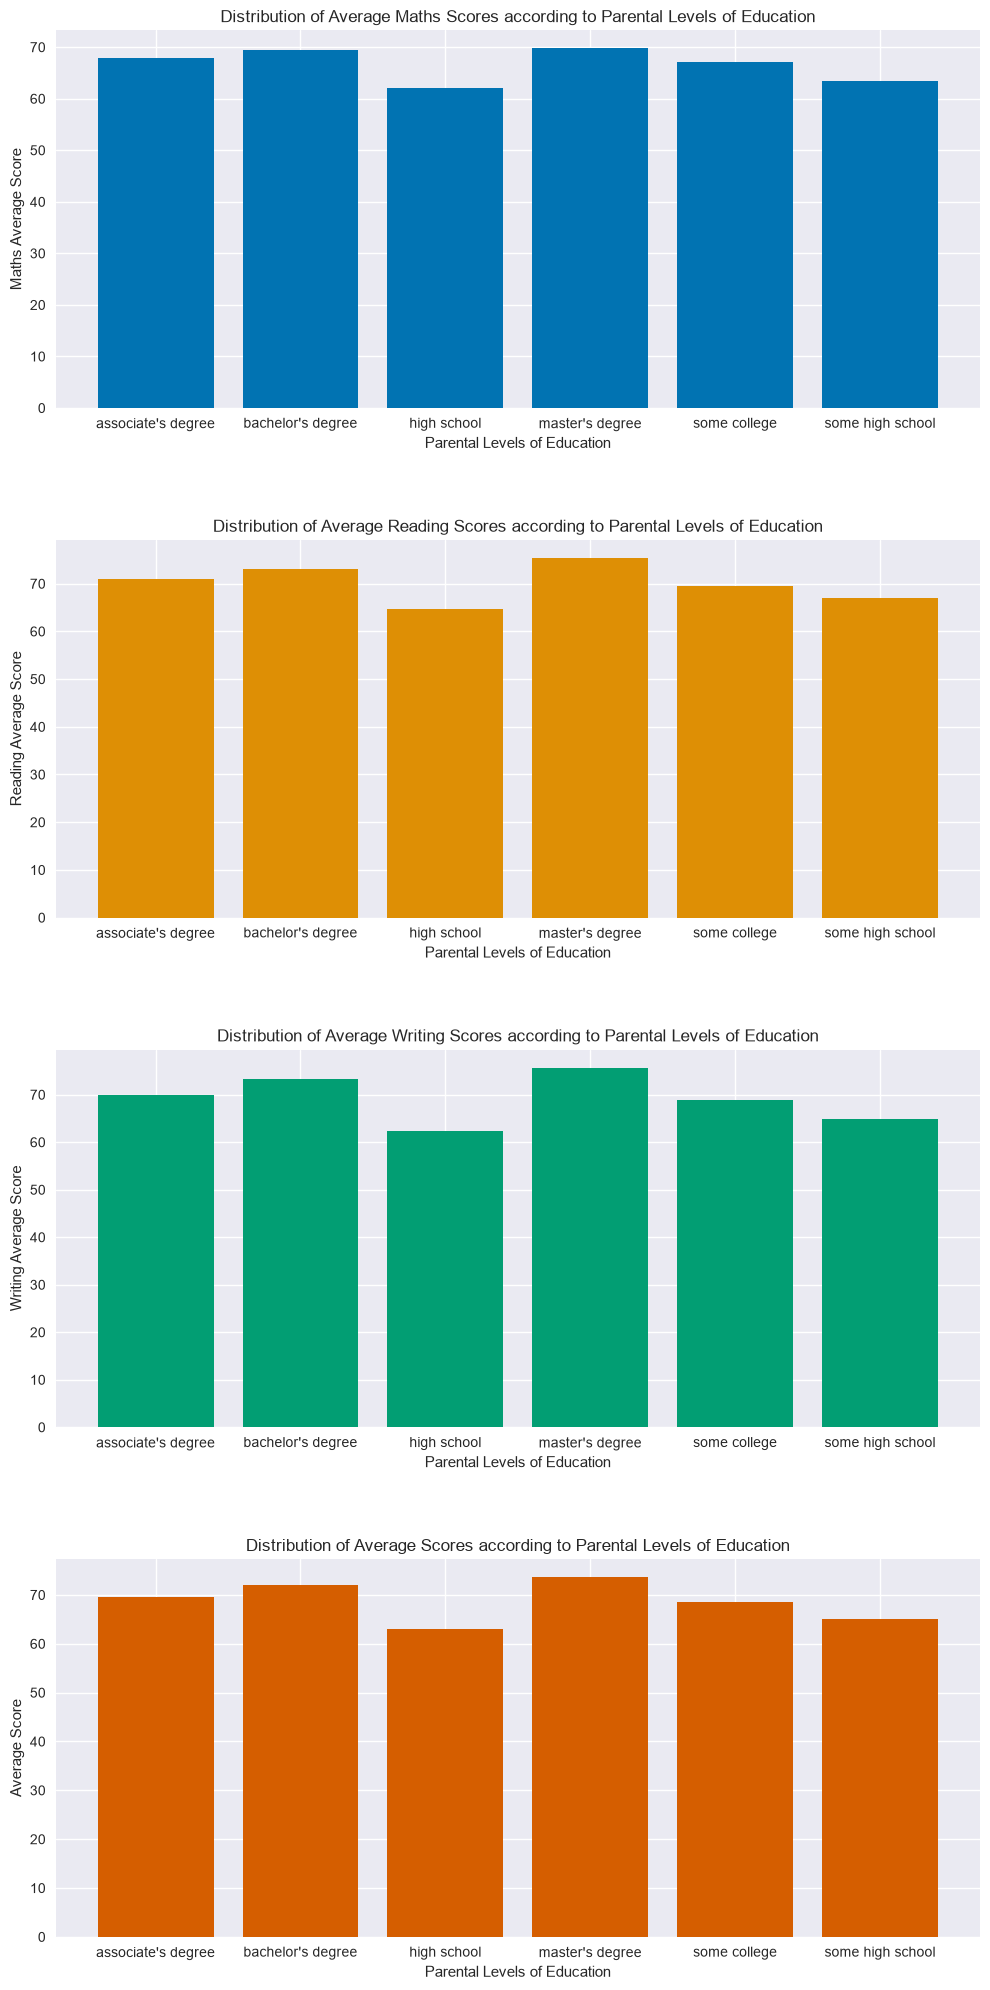

In [ ]:
# Plotting of bar charts to represent each of the groupings
fig, axes = plt.subplots(4, 1, figsize=(10, 20))

x = np.arange(len(students_data["parental_level_of_education"].unique()))
for ax, groups, subject, i in zip(axes[:3], groupings_by_parental_level[:-1], subjects, range(3)):
    ax.bar(x, groups, tick_label = sorted(students_data["parental_level_of_education"].unique()), color=palette[i])
    ax.set_xlabel("Parental Levels of Education")
    ax.set_ylabel(f"{subject} Average Score")
    ax.set_title(f"Distribution of Average {subject} Scores according to Parental Levels of Education")
    
axes[3].bar(x, groupings_by_parental_level[-1], tick_label = sorted(students_data["parental_level_of_education"].unique()), color=palette[3])
axes[3].set_xlabel("Parental Levels of Education")
axes[3].set_ylabel("Average Score")
axes[3].set_title("Distribution of Average Scores according to Parental Levels of Education")

plt.tight_layout()
plt.subplots_adjust(hspace=0.35)
plt.show()

##### Conclusion:
*Yes, there are differences in students' academic performance across their parents' education level.* <br> We can see from the bar charts that there is an association between having parents who furthered their education beyond high school and/or college and a high performance on average in the 3 subjects but this analysis alone is not sufficient to fully prove that having parents who furthered their education beyond high school and/or college alone guarantees a high academic performance. <br><br>

##### 5.  **How does academic performance vary by gender and does the pattern differ between subjects?**

For this question, we would be needing the *students_data* `gender`, `math_score`, `reading_score`, `writing_score` and `average_score` columns. We would also be creating a bar chart for each subject to show the distribution of each subject's average score according to the students gender. <br>**Then let's get into the analysis!**

In [ ]:
# We would start by grouping all the rows under the "gender" column with its respective
# average score under each subject and then the general average score
groupings_by_gender = []
update_grouping(groupings_by_gender, "gender")

These are the different groupings for the average scores for each subject corresponding to each gender:

gender
female    63.63
male      68.73
Name: math_score, dtype: float64

gender
female    72.61
male      65.47
Name: reading_score, dtype: float64

gender
female    72.47
male      63.31
Name: writing_score, dtype: float64

gender
female    69.57
male      65.84
Name: average_score, dtype: float64



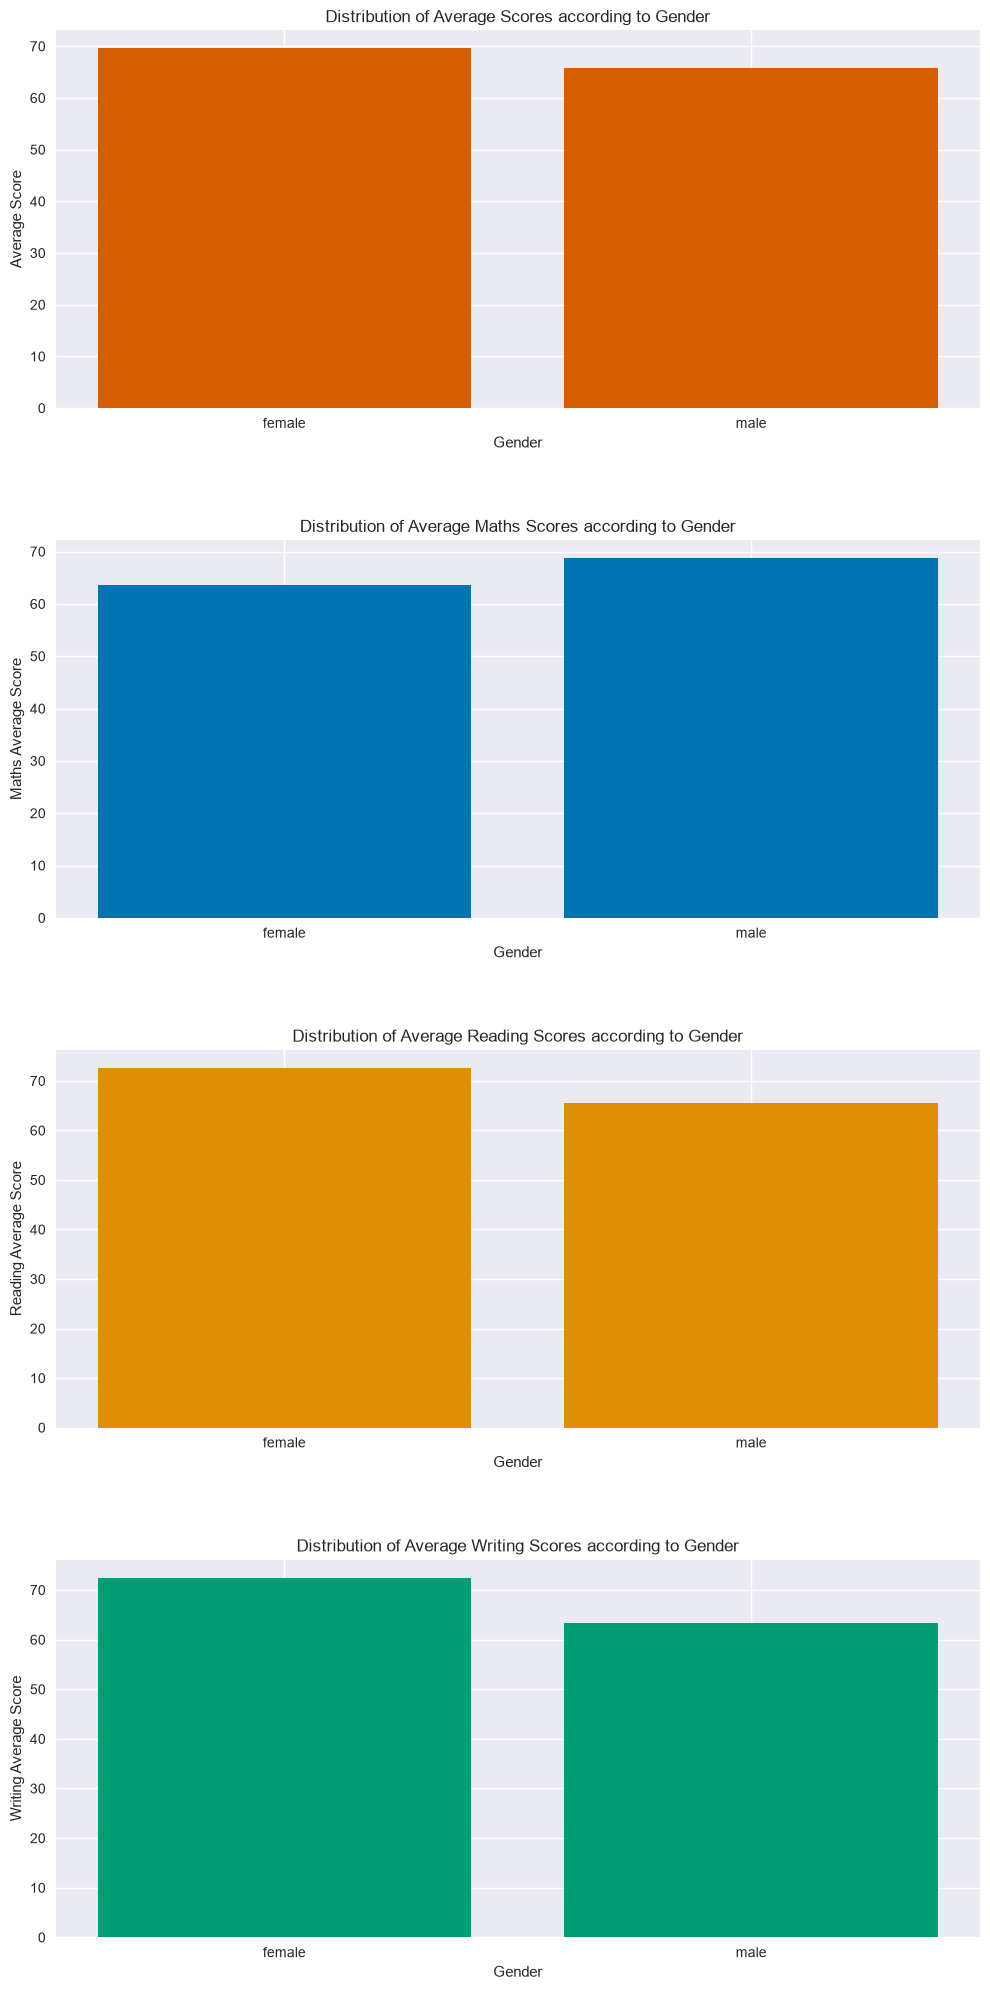

In [ ]:
# Plotting of bar charts to represent each of the groupings
fig, axes = plt.subplots(4, 1, figsize=(10, 20))

x = np.arange(len(students_data["gender"].unique()))

axes[0].bar(x, groupings_by_gender[-1], tick_label = sorted(students_data["gender"].unique()), color=palette[3])
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Average Score")
axes[0].set_title("Distribution of Average Scores according to Gender")

for ax, groups, subject, i in zip(axes[1:], groupings_by_gender[:-1], subjects, range(3)):
    ax.bar(x, groups, tick_label = sorted(students_data["gender"].unique()), color=palette[i])
    ax.set_xlabel("Gender")
    ax.set_ylabel(f"{subject} Average Score")
    ax.set_title(f"Distribution of Average {subject} Scores according to Gender")

plt.tight_layout()
plt.subplots_adjust(hspace=0.35)
plt.show()

##### Conclusion:
So from the bar charts above, we can conclude that the average score of the `female` gender is higher than that of the `male` gender meaning that the `female` gender, disregarding other variables, performed better overall than the `male` gender. This pattern holds true for the subjects Reading and Writing, but differs when it comes to Maths, where the `male` gender, disregarding other variables, performed better on average than the `female` gender. <br><br>

##### 6.  **Are there differences in students' academic performance across their race/ethnicity?**

For this question, we would be needing the *students_data* `race/ethnicity`, `math_score`, `reading_score`, `writing_score` and `average_score` columns. We would also be creating a bar chart for each subject to show the distribution of each subject's average score according to the students race/ethnicity. <br>**Then let's get into the analysis!**

In [ ]:
# We would start by grouping all the rows under the "race/ethnicity" column with its respective
# average score under each subject and then the general average score
groupings_by_race = []
update_grouping(groupings_by_race, "race/ethnicity")

print(f"This grouping below also shows how many students belong to each race/ethnicity\n\n{students_data["race/ethnicity"].value_counts()}")

These are the different groupings for the average scores for each subject corresponding to each race/ethnicity:

race/ethnicity
group A    61.63
group B    63.45
group C    64.46
group D    67.36
group E    73.82
Name: math_score, dtype: float64

race/ethnicity
group A    64.67
group B    67.35
group C    69.10
group D    70.03
group E    73.03
Name: reading_score, dtype: float64

race/ethnicity
group A    62.67
group B    65.60
group C    67.83
group D    70.15
group E    71.41
Name: writing_score, dtype: float64

race/ethnicity
group A    62.99
group B    65.47
group C    67.13
group D    69.18
group E    72.75
Name: average_score, dtype: float64

This grouping below also shows how many students belong to each race/ethnicity

race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64


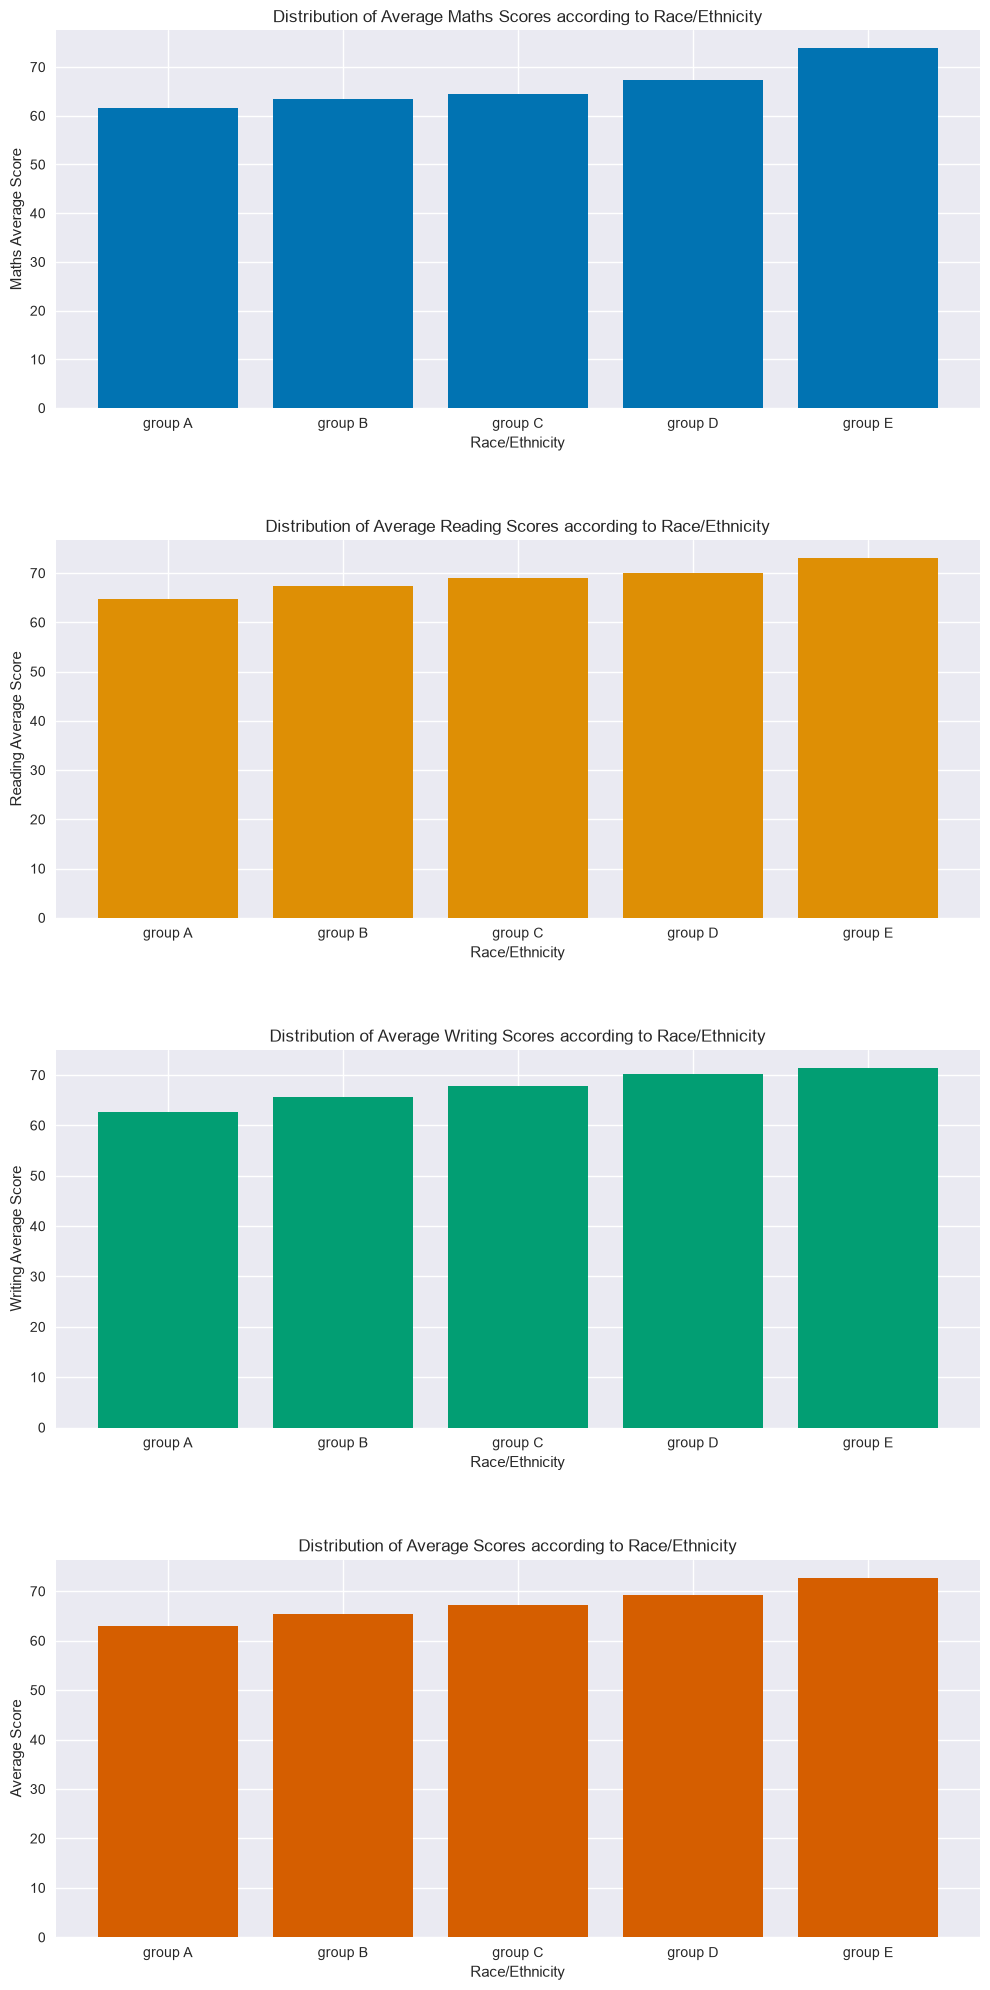

In [ ]:
# Plotting of bar charts to represent each of the groupings
fig, axes = plt.subplots(4, 1, figsize=(10, 20))

x = np.arange(len(students_data["race/ethnicity"].unique()))
for ax, groups, subject, i in zip(axes[:3], groupings_by_race[:-1], subjects, range(3)):
    ax.bar(x, groups, tick_label = sorted(students_data["race/ethnicity"].unique()), color=palette[i])
    ax.set_xlabel("Race/Ethnicity")
    ax.set_ylabel(f"{subject} Average Score")
    ax.set_title(f"Distribution of Average {subject} Scores according to Race/Ethnicity")
    
axes[3].bar(x, groupings_by_race[-1], tick_label = sorted(students_data["race/ethnicity"].unique()), color=palette[3])
axes[3].set_xlabel("Race/Ethnicity")
axes[3].set_ylabel("Average Score")
axes[3].set_title("Distribution of Average Scores according to Race/Ethnicity")

plt.tight_layout()
plt.subplots_adjust(hspace=0.35)
plt.show()

##### Conclusion:
*Yes, there are differences in students' academic performance across their race/ethnicity.* <br> We can see from the bar charts that students from group E performed better on average in their 3 subjects, followed by groups D, C, B and finally A.<br><br>

##### Save the Cleaned Data

In [ ]:
# Let's save the cleaned data
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

output_path = output_dir / "students_performance_cleaned.csv"
students_data.to_csv(output_path, index=False)
print(f"Saved cleaned data to: {output_path}")

## 3. Modelling Students' Performance

### Regression: predicting average scores

The regression models use the categorical background columns as input features and `average_score` as the target. Score-derived columns are excluded from the features to avoid directly leaking the target into the model.

The models are compared using **mean absolute error (MAE)**. A lower MAE means predictions are closer to the actual average scores, on average.

In [ ]:
# Importing all libraries for modelling
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score, GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from xgboost import XGBRegressor, XGBClassifier

print("Setup Completed")

Setup Completed


In [ ]:
# Now we obtain our X and y variables that is our features and target variables and then we split them to get our features for training and validation and targets for training and validation

target_cols = [col for col in students_data.columns if students_data[col].dtype in ["int64", "float64"] or col in ["grade", "result"]]
X = students_data.drop(columns = [col for col in target_cols])
# We exclude target_cols because it contains our target columns and also related columns that would most defintely cause data leakage

y = students_data["average_score"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, random_state=42)

In [ ]:
# Next we create a transformer that would encode(transform) all the feature columns

preprocessor = ColumnTransformer(
    transformers = [
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), X.columns)
    ]
)

In [ ]:
# Now we initialize all three models that we would be using

dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(random_state=42)
xgb_model = XGBRegressor(n_estimators = 1500, random_state=42)

In [ ]:
# Now we create three separate pipelines that would preprocess and also fit our models on the training data 

full_pipeline_dt = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", dt_model)
    ]
)

full_pipeline_rf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_model)
    ]
)

full_pipeline_xgb = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", xgb_model)
    ]
)

In [ ]:
# We now define a function that uses a GridSearchCV function that uses cross-validation to find the best parameter
def grid_search(pipeline, param_grid, scoring, X_train, y_train):
    grid_search = GridSearchCV(
        estimator = pipeline,
        param_grid = param_grid,
        n_jobs = -1,
        cv = 5, 
        scoring = scoring
    )
    grid_search.fit(X_train, y_train)
    return grid_search.best_estimator_

In [ ]:
# Now we define the scoring that we would pass into the grid search function for the regressors
scoring_regressor = "neg_mean_absolute_error"

In [ ]:
# Now we define the different parameter grids/dictionaries that we would pass for each regeressor 
param_grid_dt = {
    "model__max_leaf_nodes": [10, 50, 100, 150],
    "model__max_depth": [10, 50, 100, 200],
    "model__min_samples_leaf": [1, 10, 20, 30]
}

param_grid_rf = {
    "model__max_leaf_nodes": [10, 50, 100],
    "model__n_estimators": [200, 500]
}

param_grid_xgb = {
    "model__learning_rate": [0.0001, 0.001, 0.01, 0.1],
}

# The hyperparameter choices could be more than this but it significantly extends the runtime

In [ ]:
# Now we pass all the respective parameters to get the best estimator for each regressor based on the hyperparameters from the parameter grids
full_pipeline_dt_best = grid_search(full_pipeline_dt, param_grid_dt, scoring_regressor, X_train, y_train)
full_pipeline_rf_best = grid_search(full_pipeline_rf, param_grid_rf, scoring_regressor, X_train, y_train)
full_pipeline_xgb_best = grid_search(full_pipeline_xgb, param_grid_xgb, scoring_regressor, X_train, y_train)

In [ ]:
# Predictions for the best estimator for each regressor
dt_predictions = full_pipeline_dt_best.predict(X_valid)
rf_predictions = full_pipeline_rf_best.predict(X_valid)
xgb_predictions = full_pipeline_xgb_best.predict(X_valid)

In [ ]:
# Now we obtain the respective mean absolute errors for each regressor 
dt_error = mean_absolute_error(dt_predictions, y_valid)
rf_error = mean_absolute_error(rf_predictions, y_valid)
xgb_error = mean_absolute_error(xgb_predictions, y_valid)

errors = [dt_error, rf_error, xgb_error]
models = ["DecisionTreeRegressor", "RandomForestRegressor", "XGBRegressor"]

min_error = min(errors)
for error, i in zip(errors, range(3)):
    if min_error == error:
        best_model = models[i]

In [ ]:
# Insights on the best regressor for predicting average scores
print(f"After training three different models on the Students Performance data to find out which model has the lower prediction error when predicting students' average scores, avoiding data leakage and finally optimizing each model to get the best results, I arrived at this conclusion:")
print(f"\n1. The DecisionTreeRegressor had a mean absolute error of just approximately {round(dt_error, 1)} marks.\n2. RandomForestRegressor had a mean absolute error of just approximately {round(rf_error, 1)} marks.\n3. XGBRegressor had a mean absolute error of just approximately {round(xgb_error, 1)} marks.\n")
print(f"The minimum error therefore came out to be approximately {round(min_error, 1)} marks which means the best model for predicting students' average scores is actually:\n{best_model} model")

In [ ]:
X_clean = pd.DataFrame(full_pipeline_dt_best.named_steps["preprocessor"].transform(X), columns = full_pipeline_dt_best.named_steps["preprocessor"].get_feature_names_out())
X_clean_full = X_clean.join(students_data[target_cols])
X_clean_full.select_dtypes(["int64", "float64"]).corr() >= 0.5

,cat__gender_female,cat__gender_male,cat__race/ethnicity_group A,cat__race/ethnicity_group B,cat__race/ethnicity_group C,cat__race/ethnicity_group D,cat__race/ethnicity_group E,cat__parental_level_of_education_associate's degree,cat__parental_level_of_education_bachelor's degree,cat__parental_level_of_education_high school,...,cat__parental_level_of_education_some high school,cat__lunch_free/reduced,cat__lunch_standard,cat__test_preparation_course_completed,cat__test_preparation_course_none,math_score,reading_score,writing_score,total_score,average_score
cat__gender_female,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__gender_male,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__race/ethnicity_group A,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__race/ethnicity_group B,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__race/ethnicity_group C,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__race/ethnicity_group D,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__race/ethnicity_group E,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__parental_level_of_education_associate's degree,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
cat__parental_level_of_education_bachelor's degree,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
cat__parental_level_of_education_high school,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
dt_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ])
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ])
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier())
    ])

In [ ]:
encoder = OrdinalEncoder()
students_data_copy = students_data.copy()
students_data_copy[["result", "grade"]] = encoder.fit_transform(students_data_copy[["result", "grade"]])
y_class = students_data_copy["result"]
y_class

0      1.0
1      1.0
2      1.0
3      0.0
4      1.0
      ... 
995    1.0
996    1.0
997    1.0
998    1.0
999    1.0
Name: result, Length: 1000, dtype: float64

In [ ]:
X_class = students_data_copy.drop(columns = [col for col in target_cols])
X_class_train, X_class_valid, y_class_train, y_class_valid = train_test_split(X_class, y_class, random_state=42, stratify=y_class)

scoring_classifier = "balanced_accuracy"

In [ ]:
dt_pipeline_best = grid_search(dt_pipeline, param_grid_dt, scoring_classifier, X_class_train, y_class_train)
rf_pipeline_best = grid_search(rf_pipeline, param_grid_rf, scoring_classifier, X_class_train, y_class_train)
xgb_pipeline_best = grid_search(xgb_pipeline, param_grid_xgb, scoring_classifier, X_class_train, y_class_train)

### Classification: predicting pass/fail results

The classification task predicts the project-defined `result` column. Since `result` is calculated from students' average scores, score-derived columns are excluded from the input features. The models therefore explore how well the remaining categorical information predicts the pass/fail grouping.

The models are compared using **balanced accuracy**, which accounts for the distribution of the two result classes.

The cross-validation scores below are an additional exploratory check after hyperparameter tuning. Because tuning has already used the training data, these scores should not be treated as a fully independent estimate of generalisation performance.

In [ ]:
cv_dt_scores = cross_val_score(dt_pipeline_best, X_class_train, y_class_train, 
                            cv=5,
                            scoring='balanced_accuracy')

cv_rf_scores = cross_val_score(rf_pipeline_best, X_class_train, y_class_train, 
                            cv=5,
                            scoring='balanced_accuracy')

cv_xgb_scores = cross_val_score(xgb_pipeline_best, X_class_train, y_class_train, 
                            cv=5,
                            scoring='balanced_accuracy')

print(f"Cross-validation accuracy for the Decision Tree Classifier: {round(cv_dt_scores.mean() * 100, 1)}%")
print(f"Cross-validation accuracy for the Random Forest Classifier: {round(cv_rf_scores.mean() * 100, 1)}%")
print(f"Cross-validation accuracy for the XGBoost Classifier: {round(cv_xgb_scores.mean() * 100, 1)}%")

Cross-validation accuracy for the Decision Tree Classifier: 65.2%
Cross-validation accuracy for the Random Forest Classifier: 62.4%
Cross-validation accuracy for the XGBoost Classifier: 51.5%


In [ ]:
scores = [cv_dt_scores.mean(), cv_rf_scores.mean(), cv_xgb_scores.mean()]
models_cv = ["DecisionTreeClassifier", "RandomForestClassifier", "XGBClassifier"]
max_score = max(scores)
for score, i in zip(scores, range(3)):
    if score == max_score:
        best_model_cv = models_cv[i]

print(f"After training three different models on the Students Performance data to find out which model has the better balanced accuracy when predicting students' pass/fail results, avoiding data leakage and finally optimizing each model to get the best results, I arrived at this conclusion:")
print(f"\n1. The DecisionTreeClassifier had a mean balanced accuracy of approximately {round(cv_dt_scores.mean() * 100, 1)}%.\n2. RandomForestClassifier had a mean balanced accuracy of approximately {round(cv_rf_scores.mean() * 100, 1)}%.\n3. XGBClassifier had a mean balanced accuracy of approximately {round(cv_xgb_scores.mean() * 100, 1)}%.\n")
print(f"The maximum accuracy therefore came out to be approximately {round(max_score * 100, 1)}% which means the best model for predicting students' results is actually:\n{best_model_cv} model")

In [ ]:
dt_pipeline_best_preds = dt_pipeline_best.predict(X_class_valid)
dt_pipeline_best_preds_series = pd.Series(dt_pipeline_best_preds, index=y_class_valid.index, name="result")
report_dt = classification_report(y_class_valid, dt_pipeline_best_preds_series, zero_division=0.00)
print(report_dt)

              precision    recall  f1-score   support

         0.0       0.24      0.77      0.36        26
         1.0       0.96      0.71      0.82       224

    accuracy                           0.72       250
   macro avg       0.60      0.74      0.59       250
weighted avg       0.89      0.72      0.77       250



In [ ]:
report_dt_cm = confusion_matrix(y_class_valid, dt_pipeline_best_preds_series)
print(report_dt_cm)

[[ 20   6]
 [ 65 159]]


In [ ]:
rf_pipeline_best_preds = rf_pipeline_best.predict(X_class_valid)
rf_pipeline_best_preds_series = pd.Series(rf_pipeline_best_preds, index=y_class_valid.index, name="result")
report_rf = classification_report(y_class_valid, rf_pipeline_best_preds_series, zero_division=0.00)
print(report_rf)

              precision    recall  f1-score   support

         0.0       0.19      0.50      0.27        26
         1.0       0.93      0.75      0.83       224

    accuracy                           0.72       250
   macro avg       0.56      0.62      0.55       250
weighted avg       0.85      0.72      0.77       250



In [ ]:
report_rf_cm = confusion_matrix(y_class_valid, rf_pipeline_best_preds_series)
print(report_rf_cm)

[[ 13  13]
 [ 57 167]]


In [ ]:
xgb_pipeline_best_preds = xgb_pipeline_best.predict(X_class_valid)
xgb_pipeline_best_preds_series = pd.Series(xgb_pipeline_best_preds, index=y_class_valid.index, name="result")
report_xgb = classification_report(y_class_valid, xgb_pipeline_best_preds_series, zero_division=0.00)
print(report_xgb)

              precision    recall  f1-score   support

         0.0       0.17      0.04      0.06        26
         1.0       0.90      0.98      0.94       224

    accuracy                           0.88       250
   macro avg       0.53      0.51      0.50       250
weighted avg       0.82      0.88      0.85       250



In [ ]:
report_xgb_cm = confusion_matrix(y_class_valid, xgb_pipeline_best_preds_series)
print(report_xgb_cm)

[[  1  25]
 [  5 219]]


## Project Notes and Limitations

- This is an exploratory learning project; the findings should not be interpreted as causal relationships.
- The grading bands and pass threshold are defined in this notebook and may differ from official grading systems.
- The models use the available categorical columns. Their performance does not establish that these variables explain students' academic ability.
- The classification target (`result`) is derived from `average_score`, so the task is to predict a score-based category from the remaining available features.
